# 🦊 Contoh Lengkap: Prediksi Diabetes dengan `ColumnTransformer`

> 📘 **Ini adalah CONTOH yang sudah terjawab semua**, bukan soal. Tujuannya supaya kamu melihat dulu **alur kerja dari awal sampai akhir** sebelum mengerjakan `Latihan_ColumnTransformer.ipynb`.
> Baca pelan-pelan, jalankan tiap sel, dan perhatikan bagian **💡 Kenapa begini?**

⚠️ **Catatan penting:** data di sini **buatan (sintetis)** untuk belajar. Model ini **bukan alat diagnosis medis**.

### 🗺️ Peta perjalanan kita
| Langkah | Apa yang dilakukan |
|---|---|
| 1 | Menyiapkan data |
| 2 | Mengenali data (angka? kategori? ada yang kosong?) |
| 3 | Membagi data train dan test |
| 4 | Membuat `ColumnTransformer` (inti materi!) |
| 5 | Membungkus dengan `Pipeline` dan melatih model |
| 6 | Mengevaluasi hasil |
| 7 | Mengintip apa yang dipelajari model |
| 8 | Memprediksi pasien baru |

**Cerita:** Sebuah klinik ingin membantu **menyaring pasien yang berisiko diabetes** dari data pemeriksaan sederhana, supaya yang berisiko bisa diperiksa lebih lanjut.

## ⚙️ Langkah 0 — Impor library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             classification_report, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 30)
print("Siap!")

Siap! 🦊


## 📥 Langkah 1 — Menyiapkan data

Data dibuat otomatis oleh fungsi di bawah (pakai *random seed*, jadi hasilnya selalu sama). Isinya data 700 pasien:

| Kolom | Arti | Jenis |
|---|---|---|
| `umur` | usia (tahun) | angka |
| `bmi` | indeks massa tubuh | angka |
| `glukosa_puasa` | gula darah puasa (mg/dL) | angka |
| `tekanan_darah` | tekanan darah sistolik | angka |
| `aktivitas_fisik` | Rendah / Sedang / Tinggi | kategori **berurutan** |
| `jenis_kelamin` | Laki-laki / Perempuan | kategori **tanpa urutan** |
| `riwayat_keluarga` | ada keluarga diabetes? Ya/Tidak | kategori **tanpa urutan** |
| `perokok` | Ya / Tidak | kategori **tanpa urutan** |
| `diabetes` | **TARGET**: 1 = diabetes, 0 = tidak | label |

In [2]:
def buat_data_diabetes(n=700, seed=11):
    rng = np.random.default_rng(seed)
    umur = rng.normal(45, 13, n).clip(20, 80).round()
    bmi = rng.normal(27, 5, n).clip(16, 50).round(1)
    glukosa = (rng.normal(100, 20, n) + 0.5 * (bmi - 27) + 0.25 * (umur - 45)).clip(60, 250).round()
    tekanan = (rng.normal(120, 14, n) + 0.3 * (umur - 45)).clip(90, 200).round()
    gender = rng.choice(["Laki-laki", "Perempuan"], n)
    riwayat = rng.choice(["Ya", "Tidak"], n, p=[.3, .7])
    aktivitas = rng.choice(["Rendah", "Sedang", "Tinggi"], n, p=[.35, .40, .25])
    perokok = rng.choice(["Ya", "Tidak"], n, p=[.25, .75])

    skor = (0.07 * (glukosa - 100) + 0.08 * (bmi - 27) + 0.03 * (umur - 45)
            + 0.9 * (riwayat == "Ya") + 0.5 * (aktivitas == "Rendah") - 0.5 * (aktivitas == "Tinggi")
            + 0.01 * (tekanan - 120) + 0.3 * (perokok == "Ya") - 1.6 + rng.normal(0, 0.5, n))
    diabetes = (1 / (1 + np.exp(-1.5 * skor)) > rng.random(n)).astype(int)

    df = pd.DataFrame({
        "umur": umur, "bmi": bmi, "glukosa_puasa": glukosa, "tekanan_darah": tekanan,
        "aktivitas_fisik": aktivitas, "jenis_kelamin": gender,
        "riwayat_keluarga": riwayat, "perokok": perokok, "diabetes": diabetes,
    })
    # sengaja bikin sebagian data kosong, seperti data klinik sungguhan
    for kolom, persen in [("bmi", .05), ("tekanan_darah", .06), ("aktivitas_fisik", .04)]:
        df.loc[rng.random(n) < persen, kolom] = np.nan
    return df

df = buat_data_diabetes()
df.to_csv("data_diabetes.csv", index=False)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (700, 9)


,umur,bmi,glukosa_puasa,tekanan_darah,aktivitas_fisik,jenis_kelamin,riwayat_keluarga,perokok,diabetes
0,45.0,29.1,105.0,107.0,Sedang,Perempuan,Tidak,Tidak,0
1,63.0,26.1,95.0,118.0,Rendah,Laki-laki,Tidak,Tidak,0
2,61.0,37.2,88.0,142.0,NaN,Perempuan,Ya,Tidak,0
3,38.0,27.0,92.0,114.0,Sedang,Perempuan,Ya,Tidak,0
4,41.0,21.5,87.0,123.0,Sedang,Laki-laki,Ya,Tidak,0


## 🔍 Langkah 2 — Mengenali data

Sebelum memproses, kita **wajib kenal dulu** datanya. Ada 3 pertanyaan:
1. Kolom mana yang **angka**, mana yang **kategori**?
2. Ada **data kosong**?
3. Apakah targetnya **seimbang**?

In [3]:
print("Tipe data tiap kolom:")
print(df.dtypes, "\n")
print("Jumlah data kosong per kolom:")
print(df.isna().sum(), "\n")
print("Proporsi target:")
print(df["diabetes"].value_counts(normalize=True).round(3))

Tipe data tiap kolom:
umur                float64
bmi                 float64
glukosa_puasa       float64
tekanan_darah       float64
aktivitas_fisik         str
jenis_kelamin           str
riwayat_keluarga        str
perokok                 str
diabetes              int64
dtype: object 

Jumlah data kosong per kolom:
umur                 0
bmi                 36
glukosa_puasa        0
tekanan_darah       44
aktivitas_fisik     22
jenis_kelamin        0
riwayat_keluarga     0
perokok              0
diabetes             0
dtype: int64 

Proporsi target:
diabetes
0    0.703
1    0.297
Name: proportion, dtype: float64


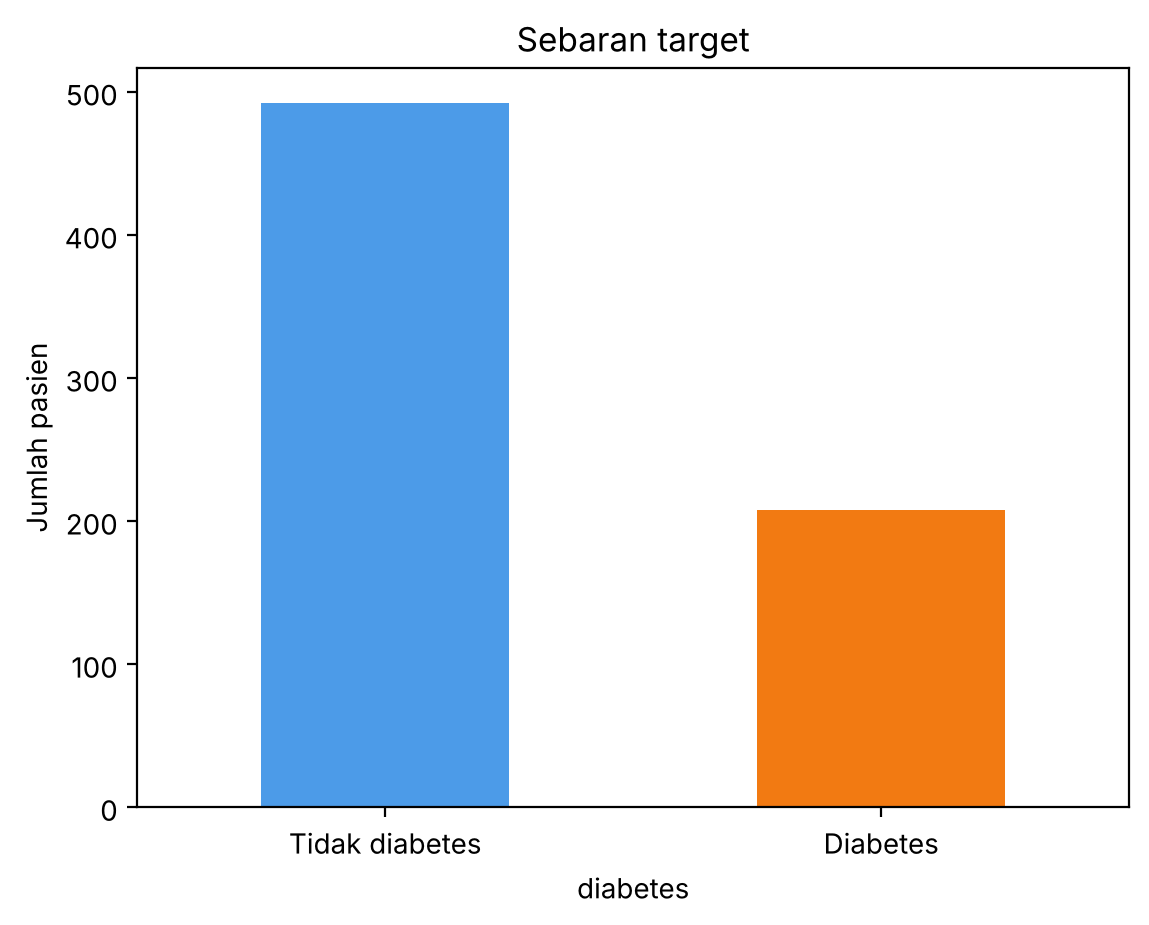

In [4]:
df["diabetes"].value_counts().rename({0: "Tidak diabetes", 1: "Diabetes"}).plot(
    kind="bar", color=["#4C9BE8", "#F27A12"], rot=0, title="Sebaran target")
plt.ylabel("Jumlah pasien")
plt.show()

**Temuan kita:**
- 🔢 **4 kolom angka**: `umur`, `bmi`, `glukosa_puasa`, `tekanan_darah`.
- 🏷️ **1 kolom kategori berurutan**: `aktivitas_fisik` (Rendah < Sedang < Tinggi).
- 🏷️ **3 kolom kategori tanpa urutan**: `jenis_kelamin`, `riwayat_keluarga`, `perokok`.
- 🕳️ Ada data kosong di `bmi`, `tekanan_darah`, dan `aktivitas_fisik`.
- ⚖️ Pasien diabetes jumlahnya lebih sedikit (sekitar 30%), jadi kita pakai `stratify` saat split.

> 💡 **Kenapa begini?** Karena tiap jenis kolom butuh **perlakuan berbeda**. Inilah alasan kita memakai `ColumnTransformer`.

## ✂️ Langkah 3 — Membagi data (split)

Kita pisahkan **fitur (`X`)** dan **target (`y`)**, lalu bagi 80% untuk belajar (train) dan 20% untuk ujian (test).

> 💡 **Kenapa split dulu, sebelum preprocessing?** Supaya informasi dari data test **tidak bocor** ke proses belajar (*data leakage*). Test harus benar-benar "soal ujian yang belum pernah dilihat".
>
> 💡 **Kenapa `stratify=y`?** Supaya proporsi pasien diabetes di train dan test tetap mirip.

In [5]:
X = df.drop(columns="diabetes")
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi diabetes -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (560, 8) | Test: (140, 8)
Proporsi diabetes -> train: 0.296 | test: 0.3


## 🧩 Langkah 4 — Membuat `ColumnTransformer` (inti materi!)

Kita buat **tiga jalur**, satu untuk tiap jenis kolom:

| Jalur | Kolom | Perlakuan | Alasan |
|---|---|---|---|
| `angka` | umur, bmi, glukosa, tekanan darah | isi kosong dengan **median** → **StandardScaler** | Skala tiap kolom beda jauh (umur 20–80, glukosa 60–250). Median tahan terhadap nilai ekstrem |
| `ordinal` | aktivitas_fisik | isi kosong dengan **modus** → **OrdinalEncoder** (Rendah=0, Sedang=1, Tinggi=2) | Kategorinya **berurutan**, jadi urutannya penting |
| `nominal` | jenis_kelamin, riwayat_keluarga, perokok | isi kosong dengan **modus** → **OneHotEncoder** | Kategorinya **tanpa urutan**. Kalau diberi angka 0/1/2, model bisa salah mengira ada urutan |

Format tiap jalur: **`(nama, transformer, kolom)`**.

In [6]:
kolom_angka = ["umur", "bmi", "glukosa_puasa", "tekanan_darah"]
kolom_ordinal = ["aktivitas_fisik"]
kolom_nominal = ["jenis_kelamin", "riwayat_keluarga", "perokok"]

jalur_angka = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

jalur_ordinal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=[["Rendah", "Sedang", "Tinggi"]])),
])

jalur_nominal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("angka", jalur_angka, kolom_angka),
        ("ordinal", jalur_ordinal, kolom_ordinal),
        ("nominal", jalur_nominal, kolom_nominal),
    ],
    remainder="drop",
).set_output(transform="pandas")

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('angka', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fea

### 👀 Mari intip hasil "masakan"-nya

Kita `fit` ke data train, lalu lihat tabel hasilnya. Perhatikan: semua sudah **angka**, **tidak ada data kosong**, dan nama kolomnya diawali nama jalur (`angka__`, `ordinal__`, `nominal__`).

> ⚠️ Di sini kita hanya **mengintip**. Untuk model sebenarnya, kita akan memakai `Pipeline` di langkah berikutnya.

In [7]:
hasil_intip = preprocessor.fit_transform(X_train)
print("Bentuk sebelum :", X_train.shape)
print("Bentuk sesudah :", hasil_intip.shape)
print("Masih ada data kosong?", hasil_intip.isna().any().any())
hasil_intip.head()

Bentuk sebelum : (560, 8)
Bentuk sesudah : (560, 11)
Masih ada data kosong? False


,angka__umur,angka__bmi,angka__glukosa_puasa,angka__tekanan_darah,ordinal__aktivitas_fisik,nominal__jenis_kelamin_Laki-laki,nominal__jenis_kelamin_Perempuan,nominal__riwayat_keluarga_Tidak,nominal__riwayat_keluarga_Ya,nominal__perokok_Tidak,nominal__perokok_Ya
340,1.321221,-1.457335,1.159890,-0.008117,0.0,0.0,1.0,1.0,0.0,1.0,0.0
140,-0.770664,1.978482,-0.883969,-0.696807,0.0,1.0,0.0,1.0,0.0,1.0,0.0
220,-0.529293,-2.184920,-0.475197,-0.008117,1.0,1.0,0.0,0.0,1.0,1.0,0.0
31,-0.287922,-0.568065,0.700022,-0.421331,1.0,0.0,1.0,1.0,0.0,1.0,0.0
203,0.999392,0.098888,0.802215,-0.214724,0.0,0.0,1.0,1.0,0.0,1.0,0.0


## 🚂 Langkah 5 — Bungkus dengan `Pipeline` dan latih model

Kita gabungkan `preprocessor` dan model dalam satu `Pipeline`. Keuntungannya:
- ✅ Saat `fit`, preprocessing **hanya belajar dari data train** (aman dari data leakage).
- ✅ Data baru **otomatis** diproses dengan cara yang sama saat prediksi.
- ✅ Kode lebih rapi: cukup `fit` dan `predict` pada data **mentah**.

Modelnya **Logistic Regression**. Kita pakai `class_weight="balanced"` karena pasien diabetes lebih sedikit, supaya model tidak mengabaikan mereka.

In [ ]:
model = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

model.fit(X_train, y_train)      # data MENTAH langsung masuk
print("Model selesai dilatih!")

Model selesai dilatih! 🎉


## 📏 Langkah 6 — Mengevaluasi hasil

Kita uji di **data test**. Ada beberapa ukuran:
- **Akurasi**: dari semua pasien, berapa persen yang ditebak benar.
- **Recall** (kepekaan): dari semua pasien yang **benar-benar diabetes**, berapa persen yang berhasil terdeteksi.
- **Precision**: dari semua yang **ditebak diabetes**, berapa persen yang benar.

> 💡 **Kenapa recall penting di kasus ini?** Karena kasus ini adalah **penyaringan**. Pasien diabetes yang terlewat (tidak terdeteksi) lebih berbahaya daripada orang sehat yang diminta periksa ulang. Jadi kita ingin recall tinggi.

In [9]:
pred = model.predict(X_test)

print(f"Akurasi  : {accuracy_score(y_test, pred):.3f}")
print(f"Recall   : {recall_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}\n")
print(classification_report(y_test, pred, target_names=["Tidak diabetes", "Diabetes"]))

Akurasi  : 0.821
Recall   : 0.881
Precision: 0.649

                precision    recall  f1-score   support

Tidak diabetes       0.94      0.80      0.86        98
      Diabetes       0.65      0.88      0.75        42

      accuracy                           0.82       140
     macro avg       0.79      0.84      0.80       140
  weighted avg       0.85      0.82      0.83       140



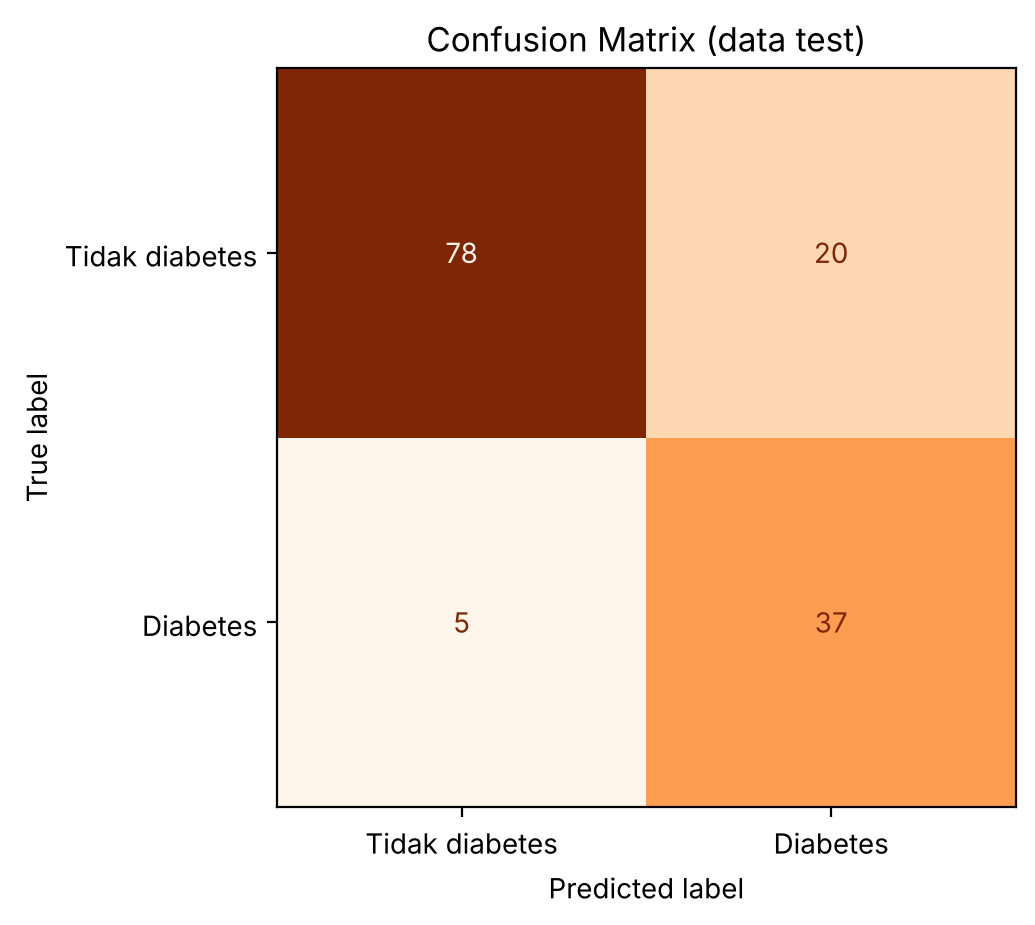

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Tidak diabetes", "Diabetes"], cmap="Oranges", colorbar=False)
plt.title("Confusion Matrix (data test)")
plt.show()

**Cara membaca confusion matrix:** baris = kenyataan, kolom = tebakan model.
- Kiri atas: sehat dan ditebak sehat ✅
- Kanan bawah: diabetes dan ditebak diabetes ✅
- Kiri bawah: **diabetes tapi ditebak sehat** ❌ (paling berbahaya, ini yang ingin kita kecilkan)
- Kanan atas: sehat tapi ditebak diabetes (diminta periksa ulang, tidak terlalu fatal)

### 🔁 Bonus kecil: apakah hasilnya konsisten? (Cross-Validation)

Satu kali split bisa kebetulan bagus atau jelek. Kita uji **5 kali** dengan pembagian berbeda. Karena semuanya ada di dalam `Pipeline`, preprocessing otomatis dilakukan **ulang dengan benar** di tiap putaran, tanpa kebocoran data.

Sekalian kita bandingkan dengan **Random Forest**, hanya dengan mengganti satu bagian pipeline.

In [11]:
model_rf = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)),
])

for nama, m in [("Logistic Regression", model), ("Random Forest", model_rf)]:
    skor = cross_val_score(m, X_train, y_train, cv=5, scoring="recall")
    print(f"{nama:20s} recall rata-rata: {skor.mean():.3f}  (+/- {skor.std():.3f})")

Logistic Regression  recall rata-rata: 0.801  (+/- 0.048)


Random Forest        recall rata-rata: 0.675  (+/- 0.048)


## 🔎 Langkah 7 — Mengintip apa yang dipelajari model

Pada Logistic Regression, **koefisien** menunjukkan arah pengaruh tiap fitur:
- Koefisien **positif** → fitur itu **menaikkan** risiko diabetes.
- Koefisien **negatif** → fitur itu **menurunkan** risiko.

Nama fitur kita ambil dari `get_feature_names_out()`. Inilah gunanya memberi nama jalur yang jelas di `ColumnTransformer`.

> Karena kolom angka sudah di-*scale*, besar koefisien kolom angka bisa dibandingkan satu sama lain secara kasar.

In [12]:
nama_fitur = model.named_steps["prep"].get_feature_names_out()
koef = model.named_steps["clf"].coef_[0]

df_koef = pd.DataFrame({"fitur": nama_fitur, "koefisien": koef}).sort_values("koefisien")
df_koef

,fitur,koefisien
4,ordinal__aktivitas_fisik,-0.646127
7,nominal__riwayat_keluarga_Tidak,-0.523126
9,nominal__perokok_Tidak,-0.218319
6,nominal__jenis_kelamin_Perempuan,0.005440
5,nominal__jenis_kelamin_Laki-laki,0.111338
3,angka__tekanan_darah,0.141619
10,nominal__perokok_Ya,0.335096
0,angka__umur,0.344922
1,angka__bmi,0.597414
8,nominal__riwayat_keluarga_Ya,0.639903


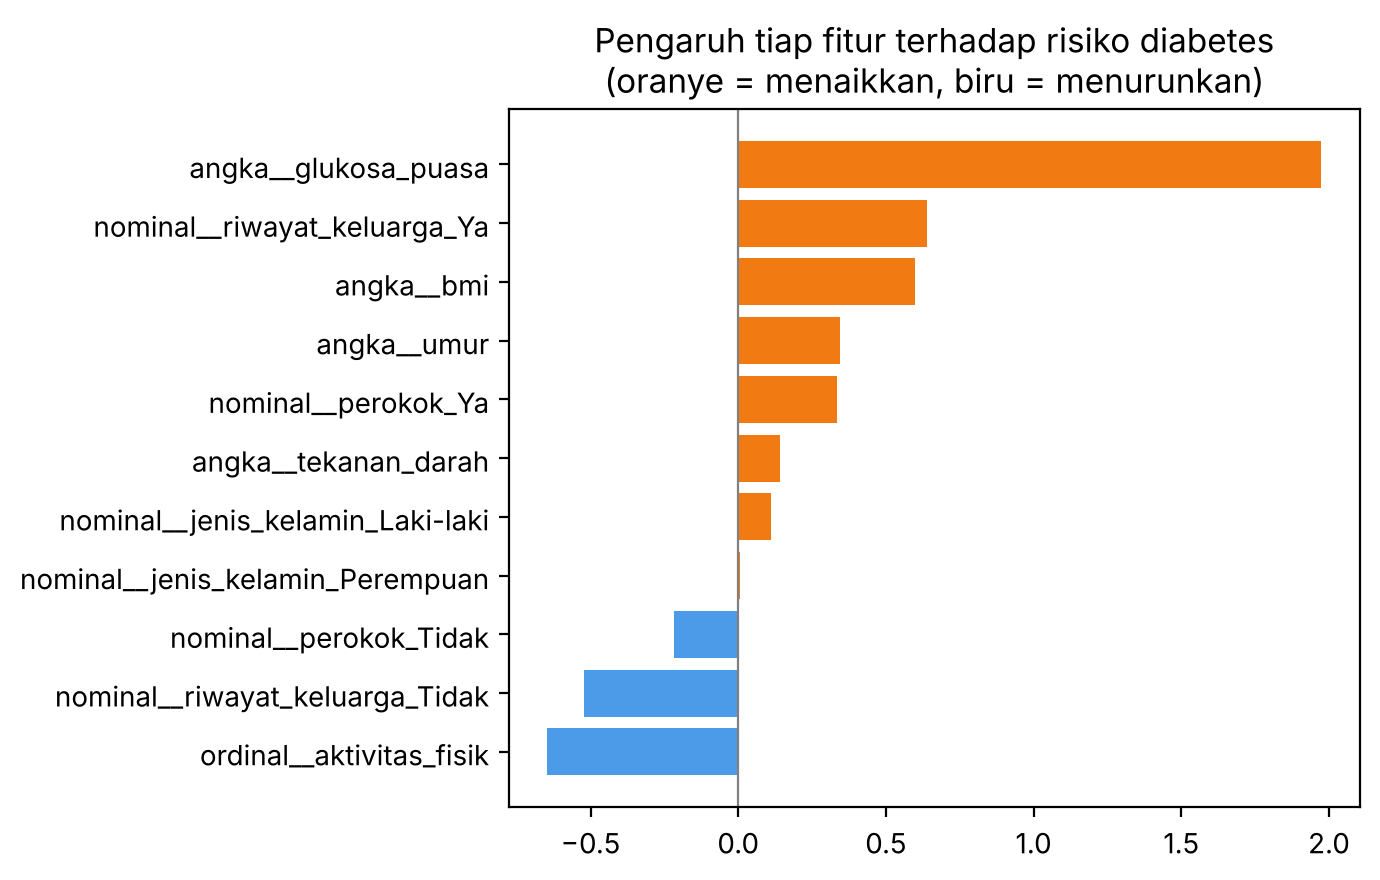

In [13]:
warna = ["#4C9BE8" if k < 0 else "#F27A12" for k in df_koef["koefisien"]]
plt.figure(figsize=(7, 4.5))
plt.barh(df_koef["fitur"], df_koef["koefisien"], color=warna)
plt.axvline(0, color="grey", lw=0.8)
plt.title("Pengaruh tiap fitur terhadap risiko diabetes\n(oranye = menaikkan, biru = menurunkan)")
plt.tight_layout()
plt.show()

**Masuk akal?** Gula darah puasa (`angka__glukosa_puasa`), BMI, umur, dan riwayat keluarga mendorong risiko naik, sedangkan aktivitas fisik yang lebih tinggi (`ordinal__aktivitas_fisik`) menurunkan risiko. Model kita belajar pola yang sesuai logika. 👍

> 🤔 **Kok ada `riwayat_keluarga_Ya` dan `riwayat_keluarga_Tidak` sekaligus?** Itu hasil `OneHotEncoder`: tiap kategori jadi satu kolom 0/1. Keduanya saling bercermin (kalau satu naik, yang lain turun), jadi arahnya berlawanan. Tidak perlu dibaca dua kali, cukup lihat salah satunya.

## 🧑‍⚕️ Langkah 8 — Memprediksi pasien baru

Ini bagian paling keren dari `Pipeline` + `ColumnTransformer`: kita cukup memberi **data mentah** (apa adanya, bahkan boleh ada yang kosong), dan semuanya diproses otomatis.

Kolom pada data baru harus **sama persis** dengan `X_train`.

In [14]:
pasien_baru = pd.DataFrame([
    {"umur": 28, "bmi": 22.0, "glukosa_puasa": 88, "tekanan_darah": 112,
     "aktivitas_fisik": "Tinggi", "jenis_kelamin": "Perempuan", "riwayat_keluarga": "Tidak", "perokok": "Tidak"},
    {"umur": 58, "bmi": 33.5, "glukosa_puasa": 142, "tekanan_darah": 138,
     "aktivitas_fisik": "Rendah", "jenis_kelamin": "Laki-laki", "riwayat_keluarga": "Ya", "perokok": "Ya"},
    {"umur": 47, "bmi": np.nan, "glukosa_puasa": 105, "tekanan_darah": np.nan,   # ada data kosong, tidak masalah!
     "aktivitas_fisik": "Sedang", "jenis_kelamin": "Laki-laki", "riwayat_keluarga": "Ya", "perokok": "Tidak"},
])

label = model.predict(pasien_baru)
peluang = model.predict_proba(pasien_baru)[:, 1]

for i, (l, p) in enumerate(zip(label, peluang), start=1):
    status = "⚠️ Berisiko, disarankan periksa lanjut" if l == 1 else "✅ Risiko rendah"
    print(f"Pasien {i}: peluang diabetes = {p*100:5.1f}%  ->  {status}")

Pasien 1: peluang diabetes =   1.3%  ->  ✅ Risiko rendah
Pasien 2: peluang diabetes =  99.9%  ->  ⚠️ Berisiko, disarankan periksa lanjut
Pasien 3: peluang diabetes =  62.9%  ->  ⚠️ Berisiko, disarankan periksa lanjut


## 💾 Bonus: Menyimpan model

Karena preprocessing sudah **menyatu** di dalam `Pipeline`, kita cukup menyimpan **satu file**. Tidak perlu menyimpan scaler atau encoder terpisah.

In [15]:
import joblib
joblib.dump(model, "model_diabetes.pkl")

model_dimuat = joblib.load("model_diabetes.pkl")
print("Prediksi dari model yang dimuat ulang:", model_dimuat.predict(pasien_baru))

Prediksi dari model yang dimuat ulang: [0 1 1]


---
## 🎓 Rangkuman Alur (simpan ini!)

```python
# 1. Split dulu
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, ...)

# 2. Satu jalur per jenis kolom
preprocessor = ColumnTransformer([
    ("angka",   Pipeline([imputer, scaler]),   kolom_angka),
    ("ordinal", Pipeline([imputer, ordinal]),  kolom_ordinal),
    ("nominal", Pipeline([imputer, onehot]),   kolom_nominal),
], remainder="drop")

# 3. Bungkus dengan model
model = Pipeline([("prep", preprocessor), ("clf", LogisticRegression())])

# 4. Latih & prediksi pakai DATA MENTAH
model.fit(X_train, y_train)
model.predict(data_baru)
```

### ✅ Checklist 5 hal yang kamu pelajari
- [x] Mengenali jenis kolom (angka, ordinal, nominal) sebelum memproses
- [x] Memberi **perlakuan berbeda** tiap jenis kolom dengan `ColumnTransformer`
- [x] Membungkusnya dalam `Pipeline` agar **bebas data leakage**
- [x] Memilih ukuran evaluasi yang sesuai kasus (**recall** untuk penyaringan penyakit)
- [x] Memprediksi data mentah baru, bahkan yang punya data kosong

### 🚀 Langkah berikutnya
Sekarang kamu sudah melihat satu contoh utuh. Saatnya **mengerjakan sendiri** di `Latihan_ColumnTransformer.ipynb`, lalu klaim badge rubah emas kamu! 🦊🏆